# DAT301m — BẢN TỔNG HỢP CUỐI, TIÊU CHÍ ACCURACY
**Nhóm:** Team 1 (Tuấn, Chiến, Trà, Huy, Duy).

## Tiêu chí
Bảng xếp hạng hiệu năng của [cuộc thi gốc](https://https-deeplearning-ai.github.io/data-centric-comp/) dùng **Accuracy**; cuộc thi còn có hạng mục Most Innovative riêng.

Notebook dùng **accuracy** để báo cáo, chọn checkpoint và chọn stage. Accuracy = số dự đoán argmax đúng / tổng ảnh. Mỗi stage giữ checkpoint có `val_accuracy` cao nhất trong 15 epoch; nếu hòa giữ epoch đạt đỉnh đầu tiên. Chọn stage theo validation accuracy, nếu hòa giữ stage có chỉ số nhỏ hơn. Label Book chỉ để báo cáo. Categorical cross-entropy là loss huấn luyện, không phải tiêu chí lựa chọn.

## Kết quả lần chạy hiện tại
Bảng dưới đối chiếu trực tiếp với output đã lưu trong **submission.ipynb**, sử dụng checkpoint theo accuracy. Cả sáu checkpoint đã được đánh giá đầy đủ trên Validation gốc và Label Book gốc.

| Stage | Số ảnh train | Epoch được chọn | Validation accuracy | Label Book accuracy |
|---|---:|---:|---:|---:|
| 0 | 2,067 | 15 | 566/813 (69.62%) | 33/52 (63.46%) |
| 1 | 1,871 | 14 | 640/813 (78.72%) | 37/52 (71.15%) |
| 2 | 3,742 | 11 | 686/813 (84.38%) | 41/52 (78.85%) |
| 3 | 7,500 | 15 | 698/813 (85.85%) | 44/52 (84.62%) |
| 4 | 9,500 | 7 | 727/813 (89.42%) | 43/52 (82.69%) |
| 5 | 10,000 | 12 | 713/813 (87.70%) | 41/52 (78.85%) |

**Mô hình được chọn: Stage 4, epoch 7**, validation **727/813 = 89,42%**, Label Book **43/52 = 82,69%**. Đây là lựa chọn khách quan theo validation accuracy, không nhìn Label Book khi chọn mô hình.

Trong sáu checkpoint được báo cáo, **Stage 3, epoch 15** đạt Label Book cao nhất: **44/52 = 84,62%** (validation **698/813 = 85,85%**). Không dùng điểm này để chọn lại mô hình.

## Dữ liệu và phạm vi
Stage 0 dùng 2.067 ảnh train gốc. Stage 1 giữ nguyên 1.871 ảnh đã clean và sửa nhãn thủ công. Stage 2 bổ sung view căn giữa đã khử nhiễu hạt/lưới/đốm biên thành 3.742 ảnh; Stage 3/4/5 có 7.500/9.500/10.000 ảnh. Không dùng thư mục `removal`. Validation 813 ảnh và Label Book 52 ảnh giữ nguyên tuyệt đối. Audit ghi nhận 49 ảnh train trùng validation ở cả nguồn gốc và nguồn thủ công, không có ảnh train trùng Label Book; chỉ báo cáo, không tự lọc.

Đây là **bản đồ án VGG16**. [README/script gốc](https://github.com/nov05/deeplearningai-data-centric-competition) dùng cut-off ResNet50 và giới hạn tổng train + validation dưới 10.000 ảnh. Stage 4/5 vượt giới hạn đó khi cộng 813 ảnh validation; các stage này được giữ làm thí nghiệm đồ án, không tuyên bố là bản nộp hợp lệ cho cuộc thi gốc.

## Cách dùng
Có thể xem kết quả và biểu đồ đã lưu mà không cần chạy lại. Để tái lập trên Colab: chọn GPU và upload `manual_train_curated.tar.gz` khi được hỏi; train gốc, validation và Label Book được khôi phục từ archive của repository. File ipynb không chứa weights. Log fit vẫn hiển thị loss để theo dõi tối ưu; bảng tổng hợp chỉ báo cáo accuracy và số đúng/tổng.

In [1]:
import sys
import os
import json
import hashlib
import shutil
import subprocess
import tarfile
import glob
from pathlib import Path, PurePosixPath

try:
    import google.colab
    IN_COLAB = True
    print("Đang chạy trên Google Colab")
except ImportError:
    IN_COLAB = False
    print("Đang chạy local")

REPO_URL = "https://github.com/nov05/deeplearningai-data-centric-competition.git"
CURATED_ARCHIVE_SHA256 = 'da8275927a552a2b4ef3b2f773ada06383e97066610d330b9b6979d511699abb'
CURATED_TRAIN_COUNTS = {'i': 244, 'ii': 144, 'iii': 144, 'iv': 274, 'v': 191, 'vi': 165, 'vii': 169, 'viii': 172, 'ix': 205, 'x': 163}
ORIGINAL_DATA_ARCHIVE_SHA256 = "4c526a362ea66d75c088929b6cabc6dca468e38239b43a74526d24cfda86c1bc"
ORIGINAL_LB_ARCHIVE_SHA256 = "4e608305e58099d31c99aa0ed141f60dc738e12a55a7906a44ff9397dea246d8"
launch_dir = Path.cwd()

def select_curated_train_archive():
    """Use the uploaded curated snapshot; never silently use the original train."""
    candidates = [launch_dir / "manual_train_curated.tar.gz",
                  Path("/content/manual_train_curated.tar.gz"),
                  launch_dir / "deeplearningai-data-centric-competition/manual_train_curated.tar.gz"]
    for candidate in candidates:
        if candidate.is_file() and hashlib.sha256(candidate.read_bytes()).hexdigest() == CURATED_ARCHIVE_SHA256:
            print("Đã tìm thấy gói train đã clean:", candidate)
            return candidate.resolve()
    if not IN_COLAB:
        return None  # Local execution uses the current data/train directory below.
    from google.colab import files
    print("Chọn file manual_train_curated.tar.gz đã tải từ máy bạn.")
    uploaded = files.upload()
    data = uploaded.get("manual_train_curated.tar.gz")
    if data is None:
        raise FileNotFoundError("Chưa chọn đúng manual_train_curated.tar.gz. Chạy lại cell và chọn gói train đi kèm notebook.")
    if hashlib.sha256(data).hexdigest() != CURATED_ARCHIVE_SHA256:
        raise ValueError("Gói train không khớp snapshot đã clean đi kèm notebook. Chọn lại đúng file.")
    package = launch_dir / "manual_train_curated.tar.gz"
    package.write_bytes(data)
    return package.resolve()


train_package = select_curated_train_archive()

# Baseline must come from the unmodified repository archives, not local data/train.
if IN_COLAB:
    REPO_ROOT = Path("/content/deeplearningai-data-centric-competition")
else:
    REPO_ROOT = (launch_dir if (launch_dir / "original/data.tar.gz").is_file()
                 else launch_dir / "deeplearningai-data-centric-competition")
if not REPO_ROOT.exists():
    if not IN_COLAB:
        raise FileNotFoundError(f"Thiếu repository tại {REPO_ROOT}")
    subprocess.run(["git", "clone", REPO_URL, str(REPO_ROOT)], check=True)
REPO_ROOT = REPO_ROOT.resolve()
if not (REPO_ROOT / "original/data.tar.gz").is_file():
    raise FileNotFoundError(f"Repository thiếu original/data.tar.gz: {REPO_ROOT}")
os.chdir(REPO_ROOT)


def restore_original_archive(archive, expected_sha, output_parent, root_name):
    """Restore byte-identical original files into an isolated generated directory."""
    archive = Path(archive)
    if hashlib.sha256(archive.read_bytes()).hexdigest() != expected_sha:
        raise ValueError(f"Archive gốc không khớp SHA-256: {archive}")
    dest = Path(output_parent).resolve() / expected_sha[:16]
    dest.mkdir(parents=True, exist_ok=True)
    expected = {}
    with tarfile.open(archive, "r:gz") as tar:
        for member in tar.getmembers():
            parts = PurePosixPath(member.name).parts
            if not parts:
                continue
            if ".." in parts or PurePosixPath(member.name).is_absolute() or "\\" in member.name:
                raise ValueError(f"Đường dẫn archive không hợp lệ: {member.name}")
            target = dest.joinpath(*parts).resolve()
            if not target.is_relative_to(dest):
                raise ValueError(f"Đường dẫn nằm ngoài snapshot: {member.name}")
            if member.isdir():
                target.mkdir(parents=True, exist_ok=True)
            elif member.isfile():
                data = tar.extractfile(member).read()
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(data)
                expected[target.relative_to(dest).as_posix()] = hashlib.sha256(data).hexdigest()
            else:
                raise ValueError(f"Không chấp nhận link/file đặc biệt: {member.name}")
    actual = {f.relative_to(dest).as_posix(): hashlib.sha256(f.read_bytes()).hexdigest()
              for f in dest.rglob("*") if f.is_file()}
    if actual != expected:
        raise ValueError("Snapshot gốc bị thừa, thiếu hoặc đổi nội dung.")
    root = dest / root_name
    if not root.is_dir():
        raise FileNotFoundError(f"Không có {root_name} trong archive gốc.")
    return root


ORIGINAL_DATA_ROOT = restore_original_archive(
    REPO_ROOT / "original/data.tar.gz", ORIGINAL_DATA_ARCHIVE_SHA256,
    REPO_ROOT / "original_snapshots", "data")
ORIGINAL_TRAIN_ROOT = ORIGINAL_DATA_ROOT / "train"
ORIGINAL_VAL_ROOT = ORIGINAL_DATA_ROOT / "val"
ORIGINAL_LABEL_BOOK_ROOT = restore_original_archive(
    REPO_ROOT / "original/label_book.tar.gz", ORIGINAL_LB_ARCHIVE_SHA256,
    REPO_ROOT / "original_snapshots", "label_book")

def unpack_curated_train(archive, expected_sha, output_parent):
    if hashlib.sha256(Path(archive).read_bytes()).hexdigest() != expected_sha:
        raise ValueError("SHA-256 gói train không hợp lệ.")
    dest = Path(output_parent).resolve() / expected_sha[:16]
    dest.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive, "r:gz") as tar:
        manifest = json.load(tar.extractfile("manifest.json"))
        for member in tar.getmembers():
            if member.name == "manifest.json":
                continue
            parts = member.name.split("/")
            if (not member.isfile() or len(parts) != 3 or parts[0] != "train"
                    or parts[1] not in manifest["classes"] or parts[2] in ("", ".", "..")
                    or "\\" in member.name):
                raise ValueError(f"Đường dẫn không hợp lệ trong gói train: {member.name}")
            target = dest.joinpath(*parts)
            target.parent.mkdir(parents=True, exist_ok=True)
            with tar.extractfile(member) as src, target.open("wb") as out:
                shutil.copyfileobj(src, out)
    train = dest / "train"
    actual = {f.relative_to(train).as_posix(): hashlib.sha256(f.read_bytes()).hexdigest()
              for f in train.rglob("*") if f.is_file()}
    if actual != manifest["files"]:
        raise ValueError("Snapshot train bị thiếu, thừa hoặc đổi nội dung.")
    print("Đã xác minh train thủ công:", sum(manifest["counts"].values()), "ảnh", manifest["counts"])
    return train


if IN_COLAB:
    CURATED_TRAIN_ROOT = unpack_curated_train(
        train_package, CURATED_ARCHIVE_SHA256, REPO_ROOT / "manual_train_snapshot")
else:
    CURATED_TRAIN_ROOT = REPO_ROOT / "data/train"
if not CURATED_TRAIN_ROOT.is_dir():
    raise FileNotFoundError("Thiếu train bạn đã clean thủ công.")
print("Stage 0 — train gốc nguyên bản:", ORIGINAL_TRAIN_ROOT)
print("Stage 1+ — train đã clean thủ công:", CURATED_TRAIN_ROOT)
print("Validation gốc cố định:", ORIGINAL_VAL_ROOT)
print("Label Book gốc cố định:", ORIGINAL_LABEL_BOOK_ROOT)

Đang chạy trên Google Colab
Chọn file manual_train_curated.tar.gz đã tải từ máy bạn.


Saving manual_train_curated.tar.gz to manual_train_curated.tar.gz
Đã xác minh train thủ công: 1871 ảnh {'i': 244, 'ii': 144, 'iii': 144, 'iv': 274, 'ix': 205, 'v': 191, 'vi': 165, 'vii': 169, 'viii': 172, 'x': 163}
Stage 0 — train gốc nguyên bản: /content/deeplearningai-data-centric-competition/original_snapshots/4c526a362ea66d75/data/train
Stage 1+ — train đã clean thủ công: /content/deeplearningai-data-centric-competition/manual_train_snapshot/da8275927a552a2b/train
Validation gốc cố định: /content/deeplearningai-data-centric-competition/original_snapshots/4c526a362ea66d75/data/val
Label Book gốc cố định: /content/deeplearningai-data-centric-competition/original_snapshots/4e608305e58099d3/label_book


<a id="setup"></a>
## 1. MÔ HÌNH VÀ CƠ SỞ LỰA CHỌN
- Giữ kiến trúc VGG16 scratch 13 Conv / 5 pool / 3 Dense, channels 64/128/256/512/512, kernel 3×3, ReLU, pool 2×2; Dense 512/512/10, dropout 0,5, He-normal theo protocol đồ án đã chạy. Không đổi sang mô hình khác.
- Input RGB 32×32, Rescaling 1/255; 32 qua 5 pool stride 2 → 1, giữ cùng loader mọi tập.
- Giữ Adam 1e-4, batch 32, 15 epoch, seed 123 để so các stage theo cùng protocol. Đây là cấu hình đối chứng cố định; cùng số epoch nhưng số optimizer updates thay đổi theo số ảnh.
- `metrics=["accuracy"]`, checkpoint `monitor="val_accuracy", mode="max"`, stage có validation accuracy cao nhất được chọn. Hòa checkpoint giữ epoch đầu; hòa stage giữ chỉ số stage nhỏ hơn. Label Book chỉ để báo cáo.
- Ảnh train nguồn chỉ có 3 mức xám `[0, 64, 255]` nên phép tẩy nền đơn thuần `arr > 215` đổi 0 pixel; vì vậy từ Stage 2 trở đi sử dụng hàm `clean_and_extract_mask` để lọc bão nhiễu hạt `gray=64`, đường lưới tọa độ đứt nét `1–2px` và đốm bẩn sát viền trước khi căn giữa với padding 15% (occupancy lý tưởng 76,92%). Các target 750/950/1000 và biên augmentation là cấu hình thực nghiệm đã chạy.
- Không trộn các metric khác trong luồng lựa chọn này. Giữ loss cross-entropy để tối ưu weights; loss không phải tiêu chí chọn checkpoint.

In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import hashlib
import shutil
from PIL import Image

IMAGE_SIZE = (32, 32)
BATCH_SIZE = 32  # Giữ chung mọi stage; thử 64 bằng một lượt chạy riêng nếu cần đo tốc độ.
# Với cùng số epoch, batch lớn hơn làm giảm số bước cập nhật. Không đổi batch giữa các stage.
NUM_CLASSES = 10
CLASS_NAMES = ["i", "ii", "iii", "iv", "v", "vi", "vii", "viii", "ix", "x"]
RANDOM_SEED = 123
EPOCHS = 15

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"🚀 Thiết bị tăng tốc: ĐÃ BẬT GPU ({gpus[0].name}) -> Tốc độ huấn luyện cực nhanh!")
else:
    print("⚠️ Thiết bị hiện tại: CPU (Khuyên dùng: Trên Colab vào Menu Runtime -> Change runtime type -> Chọn T4 GPU)")

def build_fixed_vgg16_model():
    """
    KIẾN TRÚC VGG16 TỰ XÂY DỰNG TỪ ĐẦU (FROM SCRATCH) THEO YÊU CẦU GIẢNG VIÊN:
    - KHÔNG dùng thư viện có sẵn tf.keras.applications.VGG16
    - KHÔNG dùng pretrained weights ImageNet
    - Tự code tay đúng 13 lớp Conv2D + 5 lớp MaxPooling2D + 3 lớp Dense = 16 Layers VGG16
    - Khởi tạo He-Normal, cố định bất biến qua mọi Stage
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_SEED)

    inputs = tf.keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="input_image")
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)

    # Block 1 (2 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b1_c1")(x)
    x = tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b1_c2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b1_pool")(x)

    # Block 2 (2 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b2_c1")(x)
    x = tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b2_c2")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b2_pool")(x)

    # Block 3 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c1")(x)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c2")(x)
    x = tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b3_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b3_pool")(x)

    # Block 4 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c1")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c2")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b4_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b4_pool")(x)

    # Block 5 (3 Conv + MaxPool)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c1")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c2")(x)
    x = tf.keras.layers.Conv2D(512, (3, 3), padding="same", activation="relu", kernel_initializer="he_normal", name="b5_c3")(x)
    x = tf.keras.layers.MaxPooling2D((2, 2), strides=(2, 2), name="b5_pool")(x)

    # Classifier Head (13 Conv + 3 Dense = 16 Layers VGG16)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="fc1")(x)
    x = tf.keras.layers.Dropout(0.5, name="dropout1")(x)
    x = tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", name="fc2")(x)
    x = tf.keras.layers.Dropout(0.5, name="dropout2")(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="Fixed_VGG16_Scratch")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("✅ Đã khởi tạo cấu trúc Fixed VGG16 Scratch thành công (15.245.130 tham số).")

TensorFlow Version: 2.21.0
🚀 Thiết bị tăng tốc: ĐÃ BẬT GPU (/physical_device:GPU:0) -> Tốc độ huấn luyện cực nhanh!
✅ Đã khởi tạo cấu trúc Fixed VGG16 Scratch thành công (15.245.130 tham số).


<a id="stage0"></a>
## 2. TÁCH NGUỒN TRAIN GỐC / TRAIN THỦ CÔNG VÀ ĐÓNG BĂNG TẬP ĐÁNH GIÁ
Baseline đọc trực tiếp train khôi phục từ `original/data.tar.gz` của repository. Stage 1 đọc đúng train đã sửa nhãn và loại ảnh thủ công; chỉ lấy 10 thư mục nhãn, bỏ qua removal. Không tự loại ảnh trắng, bản sao, xung đột nhãn hay ảnh trùng tập đánh giá ở bất kỳ nguồn train nào. Chụp hash của hai nguồn train và hai tập đánh giá để kiểm tra không bị sửa trong quá trình chạy. Validation và Label Book luôn lấy từ cùng snapshot nguyên bản cho mọi stage.

In [3]:
from pathlib import Path

FAIR_ROOT = Path("accuracy_results_v1").resolve()
FAIR_ROOT.mkdir(exist_ok=True)
VAL_ROOT = ORIGINAL_VAL_ROOT
LB_ROOT = ORIGINAL_LABEL_BOOK_ROOT

def file_manifest(root):
    return {str(f.relative_to(root)): hashlib.sha256(f.read_bytes()).hexdigest()
            for f in sorted(root.rglob("*")) if f.is_file()}

EVAL_SNAPSHOT = {str(root): file_manifest(root) for root in (VAL_ROOT, LB_ROOT)}
assert all(EVAL_SNAPSHOT.values()), "Thiếu dữ liệu đánh giá."
def assert_eval_unchanged():
    for root, expected in EVAL_SNAPSHOT.items():
        assert file_manifest(Path(root)) == expected, f"Tập đánh giá đã thay đổi: {root}"

def pixel_hash(path):
    with Image.open(path) as im:
        gray = im.convert("L")
        return hashlib.sha256(str(gray.size).encode() + gray.tobytes()).hexdigest()

# Source selection only: no quality filtering, deduplication or relabeling.
RAW_SOURCES = {c: sorted((ORIGINAL_TRAIN_ROOT / c).glob("*.png")) for c in CLASS_NAMES}
MANUAL_SOURCES = {c: sorted((CURATED_TRAIN_ROOT / c).glob("*.png")) for c in CLASS_NAMES}
assert all(RAW_SOURCES.values()), "Train gốc thiếu lớp."
assert all(MANUAL_SOURCES.values()), "Train thủ công thiếu lớp."
assert all(f.parent.name in CLASS_NAMES for files in MANUAL_SOURCES.values() for f in files)
SOURCE_SNAPSHOTS = {str(root): file_manifest(root)
                    for root in (ORIGINAL_TRAIN_ROOT, CURATED_TRAIN_ROOT)}

def assert_source_data_unchanged():
    for root, expected in SOURCE_SNAPSHOTS.items():
        assert file_manifest(Path(root)) == expected, f"Nguồn train đã thay đổi: {root}"

print("Stage 0 — số ảnh train gốc (không lọc):", sum(map(len, RAW_SOURCES.values())))
print("Stage 1 — số ảnh train đã clean thủ công (không lọc lại):", sum(map(len, MANUAL_SOURCES.values())))
print("Các stage sau dùng đúng nguồn train thủ công; không dùng removal.")


def fresh_train_dir(name):
    dest = (FAIR_ROOT / name).resolve()
    assert dest.parent == FAIR_ROOT and dest != FAIR_ROOT, "Đường dẫn đầu ra không an toàn."
    if dest.exists():
        shutil.rmtree(dest)
    for c in CLASS_NAMES:
        (dest / c).mkdir(parents=True, exist_ok=True)
    return dest

def load_images(directory, training=False):
    return tf.keras.utils.image_dataset_from_directory(
        str(directory), labels="inferred", label_mode="categorical",
        class_names=CLASS_NAMES, color_mode="rgb", image_size=IMAGE_SIZE,
        interpolation="bilinear", batch_size=BATCH_SIZE,
        shuffle=training, seed=RANDOM_SEED)

BASELINE_DIR = ORIGINAL_TRAIN_ROOT
train_ds_raw = load_images(BASELINE_DIR, training=True)
val_ds_raw = load_images(VAL_ROOT)
lb_ds_raw = load_images(LB_ROOT)
STAGE_RESULTS = {}
STAGE_MODELS = {}
STAGE_DETAILS = {}
STAGE_HISTORIES = {}
BEST_CHECKPOINT_DETAILS = {}
BEST_CHECKPOINT_EPOCHS = {}


def accuracy_scores(y_true, probabilities):
    y_true=np.asarray(y_true,dtype=np.int64)
    probabilities=np.asarray(probabilities)
    if y_true.ndim!=1 or len(y_true)==0 or probabilities.shape!=(len(y_true),NUM_CLASSES):
        raise ValueError("Nhãn/xác suất rỗng hoặc sai kích thước.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Có xác suất NaN/Inf.")
    predicted=probabilities.argmax(axis=1)
    correct=int(np.count_nonzero(predicted==y_true))
    return dict(metrics=dict(accuracy=correct/len(y_true),n_correct=correct,n_samples=int(len(y_true))))


def evaluate_accuracy(model,dataset,title):
    truth,probabilities=[],[]
    for images,labels in dataset:
        truth.append(np.asarray(labels).argmax(axis=1))
        probabilities.append(np.asarray(model(images,training=False)))
    if not truth: raise ValueError(f"Tập đánh giá rỗng: {title}")
    detail=accuracy_scores(np.concatenate(truth),np.concatenate(probabilities))
    m=detail["metrics"]
    print(f"{title}: accuracy={m['accuracy']:.2%}; đúng {m['n_correct']}/{m['n_samples']}")
    return detail


def plot_stage_accuracy(history,index):
    fig,ax=plt.subplots(figsize=(9,4))
    epochs=range(1,len(history.history["accuracy"])+1)
    ax.plot(epochs,history.history["accuracy"],label="Train accuracy")
    ax.plot(epochs,history.history["val_accuracy"],label="Validation accuracy")
    ax.set_xlabel("Epoch");ax.set_ylabel("Accuracy");ax.set_ylim(0,1)
    ax.set_title(f"Stage {index}");ax.legend();ax.grid(alpha=0.3)
    fig.tight_layout();fig.savefig(FAIR_ROOT/f"stage{index}_accuracy.png",dpi=130)
    plt.show()


def run_stage(index,directory):
    assert_source_data_unchanged(); assert_eval_unchanged()
    tf.keras.utils.set_random_seed(RANDOM_SEED)
    train=load_images(directory,training=True)
    model=build_fixed_vgg16_model()
    checkpoint=FAIR_ROOT/f"stage{index}_best_val_accuracy.weights.h5"
    checkpoint.unlink(missing_ok=True)
    history=model.fit(train,validation_data=val_ds_raw,epochs=EPOCHS,verbose=1,
        callbacks=[tf.keras.callbacks.CSVLogger(str(FAIR_ROOT/f"stage{index}_training.csv")),
                   tf.keras.callbacks.ModelCheckpoint(str(checkpoint),monitor="val_accuracy",mode="max",
                                                      save_best_only=True,save_weights_only=True,verbose=1)])
    final_validation=evaluate_accuracy(model,val_ds_raw,f"Stage {index} — epoch cuối — Validation")
    final_book=evaluate_accuracy(model,lb_ds_raw,f"Stage {index} — epoch cuối — Label Book")
    STAGE_DETAILS[index]=dict(validation=final_validation,label_book=final_book)
    STAGE_RESULTS[index]=dict(val_accuracy=final_validation["metrics"]["accuracy"],
                             label_book_accuracy=final_book["metrics"]["accuracy"])
    STAGE_MODELS[index]=model;STAGE_HISTORIES[index]=history
    final_weights=FAIR_ROOT/f"stage{index}_final.weights.h5"
    model.save_weights(str(final_weights))
    artifact=dict(stage=index,epochs=EPOCHS,batch_size=BATCH_SIZE,seed=RANDOM_SEED,
                  train_images=len(train.file_paths),train_directory=str(Path(directory).resolve()),
                  source_archive_sha256=ORIGINAL_DATA_ARCHIVE_SHA256 if index==0 else CURATED_ARCHIVE_SHA256,
                  actual_optimizer_updates=int(model.optimizer.iterations.numpy()),
                  optimizer_config=model.optimizer.get_config(),model_config=model.get_config(),
                  tensorflow_version=tf.__version__,selection_metric="val_accuracy",tie_rule="earliest_epoch",
                  history={k:[float(v) for v in values] for k,values in history.history.items()},
                  final_epoch=STAGE_DETAILS[index])
    if not checkpoint.is_file():raise RuntimeError("Không có checkpoint accuracy hợp lệ.")
    selected_epoch=int(np.argmax(history.history["val_accuracy"]))+1
    try:
        model.load_weights(str(checkpoint))
        validation=evaluate_accuracy(model,val_ds_raw,f"Stage {index} — best accuracy epoch {selected_epoch} — Validation")
        book=evaluate_accuracy(model,lb_ds_raw,f"Stage {index} — best accuracy epoch {selected_epoch} — Label Book")
        BEST_CHECKPOINT_DETAILS[index]=dict(validation=validation,label_book=book)
        BEST_CHECKPOINT_EPOCHS[index]=selected_epoch
        artifact.update(selected_epoch=selected_epoch,checkpoint=str(checkpoint),best_accuracy=BEST_CHECKPOINT_DETAILS[index])
    finally:
        model.load_weights(str(final_weights))
    (FAIR_ROOT/f"stage{index}_accuracy_metrics.json").write_text(json.dumps(artifact,ensure_ascii=False,indent=2),encoding="utf-8")
    plot_stage_accuracy(history,index)
    assert_source_data_unchanged();assert_eval_unchanged()
    return model,history

Stage 0 — số ảnh train gốc (không lọc): 2067
Stage 1 — số ảnh train đã clean thủ công (không lọc lại): 1871
Các stage sau dùng đúng nguồn train thủ công; không dùng removal.
Found 2067 files belonging to 10 classes.
Found 813 files belonging to 10 classes.
Found 52 files belonging to 10 classes.


## 3. BASELINE — TRAIN GỐC CHƯA LÀM SẠCH
Dùng đủ 2.067 ảnh và nhãn từ train gốc trong repository, kể cả ảnh trắng/sai nhãn/bản sao nếu có. Không offline preprocessing, không khử trùng, không augmentation. Chỉ dùng bước RGB/resize 32 × 32 bắt buộc của loader và Rescaling(1/255) trong mô hình như mọi stage.

**Kết quả hiện tại:** checkpoint epoch 15, validation **566/813 = 69,62%**, Label Book **33/52 = 63,46%**. Đây là mốc đối chứng cơ sở cho các stage sau.

Found 2067 files belonging to 10 classes.
Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - accuracy: 0.1108 - loss: 2.3784
Epoch 1: val_accuracy improved from None to 0.09963, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5
65/65 ━━━━━━━━━━━━━━━━━━━━ 58s 510ms/step - accuracy: 0.1074 - loss: 2.3258 - val_accuracy: 0.0996 - val_loss: 2.3032
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1268 - loss: 2.2966
Epoch 2: val_accuracy improved from 0.09963 to 0.10332, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage0_best_val_accuracy.weights.h5
65/65 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/ste

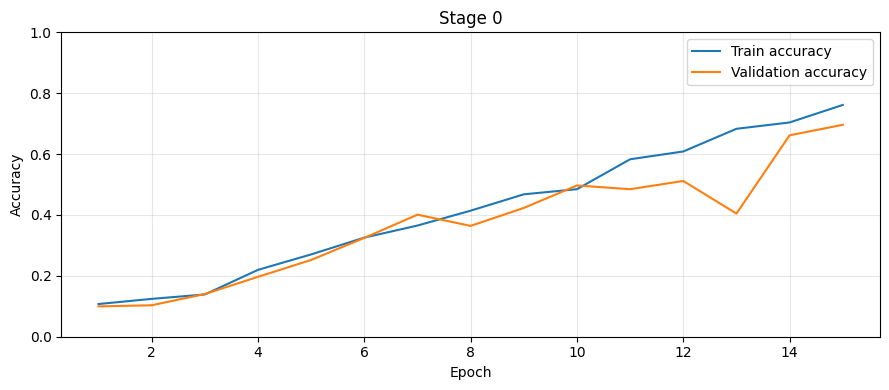

In [4]:
baseline_model, history_s0 = run_stage(0, BASELINE_DIR)

## 4. BÁO CÁO TRÙNG TẬP ĐÁNH GIÁ — CHỈ ĐỌC
Đếm các ảnh train có cùng pixel grayscale/kích thước với validation hoặc Label Book. Đây là audit, không phải bước clean: không xóa, sửa, di chuyển hay lọc ảnh. Nếu nguồn gốc có trùng train/validation thì điểm validation chưa phải ước lượng độc lập hoàn toàn; giữ nguyên và báo cáo rõ theo yêu cầu baseline nguyên bản.

In [5]:
val_hashes = {pixel_hash(f) for c in CLASS_NAMES for f in sorted((VAL_ROOT / c).glob("*.png"))}
lb_hashes = {pixel_hash(f) for c in CLASS_NAMES for f in sorted((LB_ROOT / c).glob("*.png"))}
SOURCE_AUDIT = {}
for name, sources in [("original", RAW_SOURCES), ("manual", MANUAL_SOURCES)]:
    hashes = [pixel_hash(f) for files in sources.values() for f in files]
    SOURCE_AUDIT[name] = dict(
        train_images=len(hashes),
        overlaps_validation=sum(h in val_hashes for h in hashes),
        overlaps_label_book=sum(h in lb_hashes for h in hashes))
    print(name, SOURCE_AUDIT[name])
print("Chỉ báo cáo trùng; không tự lọc lại train gốc hoặc train thủ công.")
assert_source_data_unchanged()
assert_eval_unchanged()

# TRAIN-ONLY DIAGNOSTICS: evidence for design decisions, never a cleaning step.
def summarize_training_data(root, class_names, target_side=32, thresholds=(200, 215, 230),
                            batch_size=32, epochs=15, n_original=2067, stage_targets=(750, 950, 1000)):
    root = Path(root)
    counts = {c: 0 for c in class_names}
    widths, heights = [], []
    pixel_hist = np.zeros(256, dtype=np.int64)
    border_hist = np.zeros(256, dtype=np.int64)
    geometry = {str(t): dict(empty=0, center_offset_32px=[], bbox_max_fraction=[], touches_border=0)
                for t in thresholds}
    source = hashlib.sha256()
    for c in class_names:
        for f in sorted((root / c).glob('*.png')):
            counts[c] += 1
            source.update(f.relative_to(root).as_posix().encode('utf8'))
            source.update(hashlib.sha256(f.read_bytes()).digest())
            with Image.open(f) as im:
                arr = np.asarray(im.convert('L'))
            h, w = arr.shape
            widths.append(w); heights.append(h)
            pixel_hist += np.bincount(arr.ravel(), minlength=256)
            border = np.zeros(arr.shape, dtype=bool)
            border[0,:] = border[-1,:] = True
            border[:,0] = border[:,-1] = True
            border_hist += np.bincount(arr[border], minlength=256)
            for t in thresholds:
                g = geometry[str(t)]
                mask = arr < t
                ys, xs = np.where(mask)
                if len(xs) == 0:
                    g['empty'] += 1
                    continue
                cx = (xs.min()+xs.max())/2
                cy = (ys.min()+ys.max())/2
                dx = abs(cx-(w-1)/2)/w
                dy = abs(cy-(h-1)/2)/h
                g['center_offset_32px'].append(float(max(dx,dy)*target_side))
                g['bbox_max_fraction'].append(float(max((xs.max()-xs.min()+1)/w,
                                                        (ys.max()-ys.min()+1)/h)))
                g['touches_border'] += int(mask[border].any())
    total = sum(counts.values())
    if not total or not all(counts.values()):
        raise ValueError('Train phải có ít nhất một ảnh trong mỗi lớp hợp lệ.')
    def quantiles(values):
        if not values:
            return None
        return {f'p{p}': float(np.percentile(values,p)) for p in (0,5,25,50,75,95,100)}
    for g in geometry.values():
        for key in ('center_offset_32px','bbox_max_fraction'):
            g[key] = quantiles(g[key])
        g['touches_border_fraction'] = g['touches_border']/total
    majority = max(counts.values())
    # Minimum equal target that retains all existing raw+centered views.
    m = 2*majority
    steps = {str(k): int(np.ceil(v/batch_size))*epochs for k,v in {
        '0_original':n_original,'1_manual':total,'2_raw_centered':2*total,
        '3_current_target':len(class_names)*stage_targets[0],
        '4_current_target':len(class_names)*stage_targets[1],
        '5_current_target':len(class_names)*stage_targets[2]}.items()}
    return dict(
        n_images=total,class_counts=counts,source_manifest_sha256=source.hexdigest(),
        imbalance_ratio=majority/min(counts.values()),width_px=quantiles(widths),height_px=quantiles(heights),
        geometry_by_threshold=geometry,pixel_histogram=pixel_hist.tolist(),
        perimeter_histogram=border_hist.tolist(),
        fraction_all_pixels_above_215=float(pixel_hist[216:].sum()/pixel_hist.sum()),
        fraction_perimeter_pixels_above_215=float(border_hist[216:].sum()/border_hist.sum()),
        minimum_balanced_target_manual=majority,minimum_balanced_target_raw_centered=m,
        minimum_balanced_total_raw_centered=m*len(class_names),
        observed_gray_values=np.flatnonzero(pixel_hist).astype(int).tolist(),
        pixels_changed_by_whitening_above_215=int(pixel_hist[216:255].sum()),
        pixels_changed_by_dark_boost_07=int(pixel_hist[1:120].sum()),
        planned_optimizer_steps=steps, batch_size=batch_size, epochs=epochs,
        measurement_notes=[
            'Train only; removal is excluded by explicit class list. No input images are modified or removed.',
            'Bounding boxes use a threshold proxy, not ground-truth foreground segmentation.',
            'Border pixels can contain ink; border brightness does not prove a background threshold is safe.',
            'Diagnostic thresholds 200/215/230 are sensitivity probes, not selected optimum thresholds.',
            'Optimizer step counts use the declared batch/epoch budget and keep the last partial batch; they do not prove convergence.'
        ])


TRAIN_DIAGNOSTICS = summarize_training_data(
    CURATED_TRAIN_ROOT, CLASS_NAMES, target_side=IMAGE_SIZE[0],
    batch_size=BATCH_SIZE, epochs=EPOCHS,
    n_original=sum(map(len, RAW_SOURCES.values())), stage_targets=(750, 950, 1000))
(FAIR_ROOT / "training_decision_diagnostics.json").write_text(
    json.dumps(TRAIN_DIAGNOSTICS, ensure_ascii=False, indent=2), encoding="utf-8")
print("Số ảnh theo lớp — cơ sở kiểm tra cân bằng:")
display(pd.DataFrame.from_dict(TRAIN_DIAGNOSTICS["class_counts"], orient="index", columns=["n_train"]))
print("Mức xám nguồn:", TRAIN_DIAGNOSTICS["observed_gray_values"])
print("Pixel đổi bởi tẩy nền215:", TRAIN_DIAGNOSTICS["pixels_changed_by_whitening_above_215"])
print("Target cân bằng nhỏ nhất giữ raw+center:", TRAIN_DIAGNOSTICS["minimum_balanced_target_raw_centered"])
print("Độ lệch tâm bbox quy đổi32px:", TRAIN_DIAGNOSTICS["geometry_by_threshold"]["215"]["center_offset_32px"])
print("Số optimizer updates dự kiến:", TRAIN_DIAGNOSTICS["planned_optimizer_steps"])
print("Đây là đo dữ liệu; các con số750/950/1000 và biên augmentation chưa được chứng minh tối ưu.")
assert_source_data_unchanged()
assert_eval_unchanged()

# Exact overlap pairs: list only; do not remove or relabel source images.
def image_fingerprints(path):
    path=Path(path)
    with Image.open(path) as im:
        gray=im.convert('L')
        pixel_sha=hashlib.sha256(str(gray.size).encode()+gray.tobytes()).hexdigest()
    return pixel_sha, hashlib.sha256(path.read_bytes()).hexdigest()


def find_overlap_pairs(train_sources, heldout_roots, class_names):
    index={}
    for split,root in heldout_roots.items():
        for label in class_names:
            for f in sorted((Path(root)/label).glob('*.png')):
                pixel_sha,file_sha=image_fingerprints(f)
                index.setdefault(pixel_sha,[]).append((split,label,f,file_sha))
    rows=[]
    for source,sources in train_sources.items():
        for label,files in sources.items():
            for f in files:
                pixel_sha,file_sha=image_fingerprints(f)
                for split,held_label,held_path,held_file_sha in index.get(pixel_sha,[]):
                    rows.append(dict(train_source=source,train_label=label,train_path=str(Path(f).resolve()),
                                     heldout_split=split,heldout_label=held_label,
                                     heldout_path=str(held_path.resolve()),same_label=label==held_label,
                                     byte_identical=file_sha==held_file_sha,
                                     pixel_sha256=pixel_sha))
    return rows


OVERLAP_PAIRS = find_overlap_pairs(
    {"original": RAW_SOURCES, "manual": MANUAL_SOURCES},
    {"validation": VAL_ROOT, "label_book": LB_ROOT}, CLASS_NAMES)
overlap_columns = ["train_source", "train_label", "train_path", "heldout_split", "heldout_label",
                   "heldout_path", "same_label", "byte_identical", "pixel_sha256"]
overlap_table = pd.DataFrame(OVERLAP_PAIRS, columns=overlap_columns)
overlap_table.to_csv(FAIR_ROOT / "overlap_pairs.csv", index=False, encoding="utf-8-sig")
(FAIR_ROOT / "overlap_pairs.json").write_text(
    json.dumps(OVERLAP_PAIRS, ensure_ascii=False, indent=2), encoding="utf-8")
print("Các cặp overlap chính xác (đường dẫn và nhãn); toàn bộ lưu ở overlap_pairs.csv:")
display(overlap_table)
assert_source_data_unchanged()
assert_eval_unchanged()

original {'train_images': 2067, 'overlaps_validation': 49, 'overlaps_label_book': 0}
manual {'train_images': 1871, 'overlaps_validation': 49, 'overlaps_label_book': 0}
Chỉ báo cáo trùng; không tự lọc lại train gốc hoặc train thủ công.
Số ảnh theo lớp — cơ sở kiểm tra cân bằng:


,n_train
i,244
ii,144
iii,144
iv,274
v,191
vi,165
vii,169
viii,172
ix,205
x,163


Mức xám nguồn: [0, 64, 255]
Pixel đổi bởi tẩy nền215: 0
Target cân bằng nhỏ nhất giữ raw+center: 548
Độ lệch tâm bbox quy đổi32px: {'p0': 0.0, 'p5': 0.46802139037433155, 'p25': 1.676856547769154, 'p50': 2.83982683982684, 'p75': 4.276521185090793, 'p95': 6.753393753667601, 'p100': 12.846153846153847}
Số optimizer updates dự kiến: {'0_original': 975, '1_manual': 885, '2_raw_centered': 1755, '3_current_target': 3525, '4_current_target': 4455, '5_current_target': 4695}
Đây là đo dữ liệu; các con số750/950/1000 và biên augmentation chưa được chứng minh tối ưu.
Các cặp overlap chính xác (đường dẫn và nhãn); toàn bộ lưu ở overlap_pairs.csv:


,train_source,train_label,train_path,heldout_split,heldout_label,heldout_path,same_label,byte_identical,pixel_sha256
0,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,42b814e0e2145bb0dda20b8e446c1e12649001bd50c58f...
1,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,d05c6198ebed366f876879abc92ccceb17060cdfe64dcc...
2,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,36d4ebd202d12069f36fd1869b3fc54059e02ce3914f69...
3,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,eed2333d1fa20be55798e98aca4f44c6040f33d4641dcf...
4,original,i,/content/deeplearningai-data-centric-competiti...,validation,i,/content/deeplearningai-data-centric-competiti...,True,True,07a462fec63052f2095cb3d5d1ef1b55679d8420664782...
...,...,...,...,...,...,...,...,...,...
93,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,8bf2b478c7264e34a3f2845644b71652760d834f961cfd...
94,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,c7cb773f8d6204aa6aeab720ee453fe9de9cbe74f92e1f...
95,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,186f148c9761499564e61f34ed3fe86ba428af8954abf9...
96,manual,x,/content/deeplearningai-data-centric-competiti...,validation,x,/content/deeplearningai-data-centric-competiti...,True,True,0107a01f31d00c7c12a485f9613ab6bb0bfd473085bb50...


<a id="stage1"></a>
# STAGE 1: TRAIN ĐÃ CLEAN VÀ SỬA NHÃN THỦ CÔNG
Dùng nguyên vẹn các ảnh trong 10 lớp của gói train bạn đã clean: ảnh kém chất lượng đã đưa vào removal, ảnh sai nhãn đã chuyển sang thư mục đúng. Không chạy cleaner, blacklist, loại ảnh trắng, khử trùng hay loại nhóm mâu thuẫn nhãn thêm lần nữa. Stage 1 giữ nguyên bytes/nhãn và không thêm ảnh. Chỉ thay nguồn train so với baseline; mô hình, loader, batch size, seed, optimizer, epoch và hai tập đánh giá giữ giống nhau.

## 1. CHỌN TRAIN THỦ CÔNG — KHÔNG CLEAN LẠI

In [6]:
MANUAL_TRAIN_DIR = CURATED_TRAIN_ROOT
assert all((MANUAL_TRAIN_DIR / c).is_dir() for c in CLASS_NAMES)
print("Stage 1 sử dụng nguyên vẹn train thủ công:", MANUAL_TRAIN_DIR)
print("Số ảnh:", sum(len(list((MANUAL_TRAIN_DIR / c).glob("*.png"))) for c in CLASS_NAMES))
assert_source_data_unchanged()
assert_eval_unchanged()

Stage 1 sử dụng nguyên vẹn train thủ công: /content/deeplearningai-data-centric-competition/manual_train_snapshot/da8275927a552a2b/train
Số ảnh: 1871


## 2. HUẤN LUYỆN TRÊN TRAIN THỦ CÔNG
Không thay đổi ảnh hoặc nhãn đã clean trong quá trình huấn luyện. Validation và Label Book gốc cố định.

Checkpoint epoch 14 đạt validation **640/813 = 78,72%**, Label Book **37/52 = 71,15%**. So với baseline (Stage 0), validation tăng mạnh **9,10 điểm phần trăm** (+74 ảnh đúng, từ 566 lên 640) và Label Book tăng **7,69 điểm phần trăm** (+4 ảnh đúng, từ 33 lên 37), mặc dù tổng số ảnh giảm từ 2.067 xuống 1.871 ảnh (số bước cập nhật trong 15 epoch giảm từ 975 xuống 885). Kết quả này khẳng định việc sửa các nhãn sai và loại bỏ ảnh lỗi/trùng lặp chéo lớp giúp cải thiện đồng thời cả Validation lẫn Label Book.

Found 1871 files belonging to 10 classes.
Epoch 1/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.1065 - loss: 2.3913
Epoch 1: val_accuracy improved from None to 0.10332, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage1_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage1_best_val_accuracy.weights.h5
59/59 ━━━━━━━━━━━━━━━━━━━━ 29s 354ms/step - accuracy: 0.1128 - loss: 2.3298 - val_accuracy: 0.1033 - val_loss: 2.3055
Epoch 2/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1354 - loss: 2.2900
Epoch 2: val_accuracy did not improve from 0.10332
59/59 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.1400 - loss: 2.2949 - val_accuracy: 0.1033 - val_loss: 2.3070
Epoch 3/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1337 - loss: 2.2903
Epoch 3: val_accuracy did not improve from 0.10332
59/59 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 

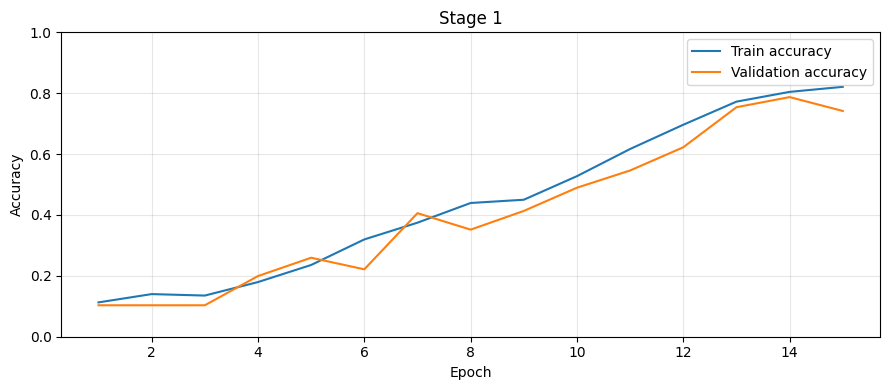

In [7]:
model_s1, history_s1 = run_stage(1, MANUAL_TRAIN_DIR)

<a id="stage2"></a>
# STAGE 2: RAW + CENTERED — 3.742 ẢNH TRAIN
Giữ nguyên mọi ảnh train thủ công (`1.871` ảnh `raw_`) và bổ sung một bản căn giữa đã khử nhiễu thông minh (`1.871` ảnh `center_`), cùng nhãn. Train có p95 lệch tâm bbox ≈ 6,75 pixel ở ảnh 32×32 nên có cơ sở rõ ràng để căn giữa; giữ bản `raw_` giúp mô hình tiếp tục học được cả bố cục nguyên bản. Vì ảnh nguồn chỉ có 3 mức xám `[0, 64, 255]`, hàm `clean_and_extract_mask` kết hợp phân tích thành phần liên thông (`scipy.ndimage.label`) và biến đổi khoảng cách (`distance_transform_edt`) để khử bão nhiễu hạt `gray=64`, xóa lưới tọa độ đứt nét `1–2px` và loại bỏ các đốm bẩn sát viền làm lệch bounding box trước khi căn giữa với padding 15% và thu nhỏ bằng `LANCZOS`. Không biến đổi validation/Label Book.

**Kết quả hiện tại:** checkpoint epoch 11, validation **686/813 = 84,38%**, Label Book **41/52 = 78,85%**. So với Stage 1, tăng **5,66 điểm phần trăm** (+46 ảnh đúng) trên validation và tăng **7,69 điểm phần trăm** (+4 ảnh đúng) trên Label Book.

In [8]:
from scipy import ndimage as ndi

def clean_and_extract_mask(gray_arr):
    """Tách nét chữ thông minh: khử bão nhiễu xám=64, lưới tọa độ đứt nét 1-2px và đốm bẩn sát viền."""
    arr = gray_arr.copy()
    h, w = arr.shape
    mask0 = (arr == 0)
    mask64 = (arr == 64)
    _, cc0 = ndi.label(mask0)
    _, cc64 = ndi.label(mask64)

    # 1. Khử bão nhiễu hạt (gray=64) phủ trên nét chữ đen (gray=0)
    if cc64 > 60 and 1 <= cc0 <= 12 and mask0.sum() >= 250:
        arr[arr == 64] = 255

    arr[arr > 215] = 255
    mask = arr < 215
    if not mask.any():
        return arr, mask

    labeled, n_cc = ndi.label(mask)
    # 2. Khử đường lưới tọa độ đứt nét (1-2px) cắt ngang nét chữ dày (6-10px)
    if n_cc >= 18:
        dist = ndi.distance_transform_edt(mask)
        if np.percentile(dist[mask], 90) >= 2.8:
            core = dist > 1.8
            if core.any():
                regrown = ndi.binary_dilation(core, iterations=2) & mask
                lbl_r, n_r = ndi.label(regrown)
                if n_r > 0:
                    sizes_r = np.bincount(lbl_r.ravel())
                    sizes_r[0] = 0
                    max_r = sizes_r.max()
                    keep_r = np.where(sizes_r >= max(25, 0.08 * max_r))[0]
                    if len(keep_r) > 0:
                        clean_mask = np.isin(lbl_r, keep_r)
                        arr[mask & ~clean_mask] = 255
                        mask = clean_mask
                        labeled, n_cc = ndi.label(mask)

    # 3. Loại bỏ các đốm nhiễu rời rạc và vệt bẩn nhỏ sát biên làm lệch bounding box
    if n_cc > 1:
        sizes = np.bincount(labeled.ravel())
        sizes[0] = 0
        max_size = sizes.max()
        total_ink = mask.sum()
        keep = []
        for cid in range(1, n_cc + 1):
            s = sizes[cid]
            if s < max(16, 0.035 * max_size) and s < 0.025 * total_ink:
                continue
            comp = (labeled == cid)
            cy, cx = np.where(comp)
            touches_border = (cy.min() <= 2 or cy.max() >= h - 3 or cx.min() <= 2 or cx.max() >= w - 3)
            if touches_border and s < 0.25 * max_size:
                continue
            keep.append(cid)
        if keep:
            clean_mask = np.isin(labeled, keep)
            arr[mask & ~clean_mask] = 255
            mask = clean_mask

    return arr, mask

def denoise_native_numeral(img_pil, boost_contrast=False, contrast_factor=0.72):
    """Giữ nguyên bố cục khung hình gốc nhưng lọc bỏ bão nhiễu hạt, đường lưới và đốm bẩn biên."""
    arr, mask = clean_and_extract_mask(np.asarray(img_pil.convert("L")))
    if not mask.any():
        return img_pil.convert("RGB")
    if boost_contrast:
        dark = arr < 120
        arr[dark] = (arr[dark] * contrast_factor).astype(np.uint8)
    return Image.fromarray(arr).convert("RGB")

def preprocess_and_center_numeral(img_pil, target_size=(32, 32), pad_ratio=0.15):
    """Khử nhiễu thông minh, cắt sát chữ số, căn giữa trên canvas vuông và downsample bằng LANCZOS."""
    arr, mask = clean_and_extract_mask(np.asarray(img_pil.convert("L")))
    ys, xs = np.where(mask)
    if len(ys) == 0:
        return None
    ymin, ymax = int(ys.min()), int(ys.max())
    xmin, xmax = int(xs.min()), int(xs.max())
    h = ymax - ymin + 1
    w = xmax - xmin + 1
    max_dim = max(h, w)
    pad = max(4, round(max_dim * pad_ratio))
    total_size = max_dim + 2 * pad
    canvas = np.full((total_size, total_size), 255, dtype=np.uint8)
    crop = arr[ymin:ymax+1, xmin:xmax+1]
    y0 = (total_size - h) // 2
    x0 = (total_size - w) // 2
    canvas[y0:y0+h, x0:x0+w] = crop
    canvas[canvas < 120] = (canvas[canvas < 120] * 0.7).astype(np.uint8)
    res = Image.fromarray(canvas).resize(target_size, Image.Resampling.LANCZOS)
    return res.convert("RGB")

## 1. TẠO TRAIN HỖN HỢP: ẢNH GỐC + BẢN CĂN GIỮA

In [9]:
STAGE2_DIR = fresh_train_dir("stage2_mixed_train")
for c in CLASS_NAMES:
    for f in sorted((MANUAL_TRAIN_DIR / c).glob("*.png")):
        shutil.copyfile(f, STAGE2_DIR / c / ("raw_" + f.name))
        with Image.open(f) as im:
            proc = preprocess_and_center_numeral(im, target_size=IMAGE_SIZE)
        if proc is not None:
            proc.save(STAGE2_DIR / c / ("center_" + f.name))
print("Stage 2 train (giữ đầy đủ ảnh gốc):", len(list(STAGE2_DIR.glob("*/*.png"))))
assert_eval_unchanged()

Stage 2 train (giữ đầy đủ ảnh gốc): 3742


## 2. HUẤN LUYỆN VÀ ĐÁNH GIÁ TRÊN HAI TẬP GỐC

Found 3742 files belonging to 10 classes.
Epoch 1/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.1130 - loss: 2.3597
Epoch 1: val_accuracy improved from None to 0.15129, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5
117/117 ━━━━━━━━━━━━━━━━━━━━ 34s 215ms/step - accuracy: 0.1245 - loss: 2.3108 - val_accuracy: 0.1513 - val_loss: 2.3070
Epoch 2/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1666 - loss: 2.2448
Epoch 2: val_accuracy improved from 0.15129 to 0.25215, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage2_best_val_accuracy.weights.h5
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 

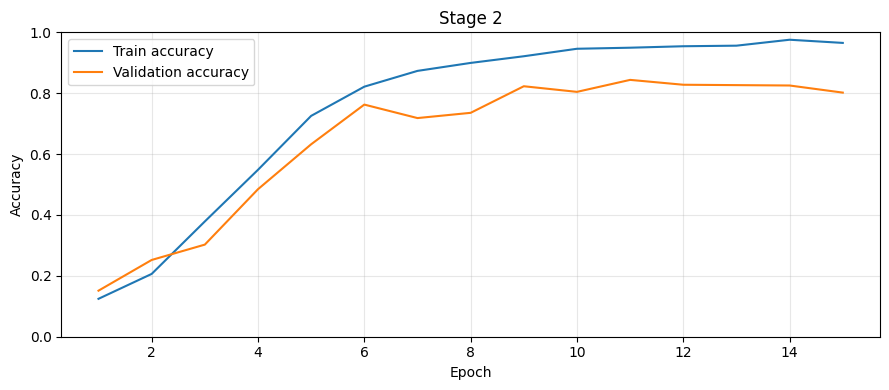

In [10]:
model_s2, history_s2 = run_stage(2, STAGE2_DIR)

<a id="stage3"></a>
# STAGE 3: CÂN BẰNG VÀ AUGMENTATION — 7.500 ẢNH TRAIN
Nguồn gồm `raw` (đã khử nhiễu hạt/lưới ở độ phân giải gốc) và `centered` của Stage 2; cân bằng đúng 750 ảnh/lớp (tổng 7.500 ảnh). Sử dụng biến đổi affine bảo toàn biên (`augment_stage3_view`: xoay ±6°, co giãn đẳng hướng ±6%, dịch chuyển ±5%, nội suy `BICUBIC` + kiểm tra không chạm viền + downsample `LANCZOS`), không lật ngang.

Checkpoint epoch 15 đạt validation **698/813 = 85,85%**, Label Book **44/52 = 84,62%**. So với Stage 2, tăng **1,48 điểm phần trăm** (+12 ảnh đúng) trên validation và tăng **5,77 điểm phần trăm** (+3 ảnh đúng) trên Label Book. Đây là mức **Label Book cao nhất (44/52 = 84,62%)** trong cả sáu stage; tuy nhiên theo quy tắc chỉ chọn mô hình bằng validation accuracy, không dùng điểm Label Book này để chọn lại mô hình.

Target cân bằng nhỏ nhất giữ đủ hai view của lớp lớn nhất (`iv`: 274 ảnh) là 548 ảnh/lớp; mốc 750 ảnh/lớp kết hợp đồng thời cân bằng phân phối lớp, đa dạng hóa góc nghiêng/tỷ lệ và tăng số bước cập nhật lên 3.525 steps.

## 1. TẠO TẬP CÂN BẰNG 7.500 ẢNH


In [11]:
import random
from PIL import ImageOps

def augment_stage3_view(im_rgb, rng, rotation=6.0):
    """Biến đổi affine bảo toàn biên trên nguồn Stage 2 (raw ở độ phân giải gốc + centered 32x32)."""
    border = max(2, round(max(im_rgb.size) * 0.08))
    im = ImageOps.expand(im_rgb, border=border, fill="white")
    w, h = im.size
    out = im
    for attempt in range(4):
        decay = 0.6 ** attempt
        max_angle = rotation * decay
        angle = np.deg2rad(rng.uniform(-max_angle, max_angle))
        scale = 1.0 + rng.uniform(-0.06, 0.06) * decay
        max_shift = 0.05 * decay
        rotation_mat = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
        linear = rotation_mat * scale
        center = np.array([(w - 1) / 2, (h - 1) / 2])
        shift = np.array([rng.uniform(-max_shift, max_shift) * w, rng.uniform(-max_shift, max_shift) * h])
        forward = np.eye(3)
        forward[:2, :2] = linear
        forward[:2, 2] = center + shift - linear @ center
        inverse = np.linalg.inv(forward)
        candidate = im.transform(
            (w, h),
            Image.Transform.AFFINE,
            tuple(inverse[:2].reshape(-1)),
            resample=Image.Resampling.BICUBIC,
            fillcolor="white",
        )
        mask = np.asarray(candidate.convert("L")) < 160
        if not (mask[0, :].any() or mask[-1, :].any() or mask[:, 0].any() or mask[:, -1].any()):
            out = candidate
            break
    return out.resize(IMAGE_SIZE, Image.Resampling.LANCZOS)

def build_balanced_train(name, target, rotation):
    dest = fresh_train_dir(name)
    rng = random.Random(RANDOM_SEED)
    for c in CLASS_NAMES:
        files = sorted((STAGE2_DIR / c).glob("*.png"))
        if not 0 < len(files) <= target:
            raise ValueError(f"Lớp {c}: cần 1..{target} ảnh nguồn, có {len(files)}")
        pool = []
        for i, f in enumerate(files):
            shutil.copyfile(f, dest / c / f"original_{i:04d}.png")
            with Image.open(f) as im:
                # Khử nhiễu hạt/lưới trên bản raw trước khi đưa vào pool augment
                src_im = denoise_native_numeral(im) if f.name.startswith("raw_") else im.convert("RGB")
                pool.append(src_im)
        for i in range(target - len(pool)):
            aug_im = augment_stage3_view(pool[i % len(pool)], rng, rotation=rotation)
            aug_im.save(dest / c / f"aug_{i:04d}.png")
        assert len(list((dest / c).glob("*.png"))) == target
    assert_eval_unchanged()
    print("Train:", dest, target * len(CLASS_NAMES))
    return dest

STAGE3_DIR = build_balanced_train("stage3_balanced_train", 750, 6)

Train: /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_balanced_train 7500


## 2. HUẤN LUYỆN TRÊN 7.500 ẢNH TRAIN

Found 7500 files belonging to 10 classes.
Epoch 1/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.1118 - loss: 2.3302
Epoch 1: val_accuracy improved from None to 0.22755, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5
235/235 ━━━━━━━━━━━━━━━━━━━━ 35s 112ms/step - accuracy: 0.1332 - loss: 2.2676 - val_accuracy: 0.2276 - val_loss: 2.0739
Epoch 2/15
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3333 - loss: 1.7579
Epoch 2: val_accuracy improved from 0.22755 to 0.44403, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage3_best_val_accuracy.weights.h5
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s

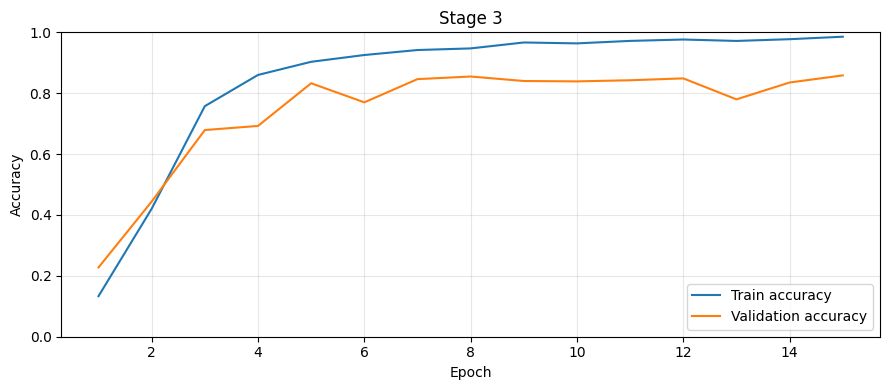

In [12]:
model_s3, history_s3 = run_stage(3, STAGE3_DIR)

<a id="stage4"></a>
# STAGE 4: NATIVE MIXED — 9.500 ẢNH TRAIN
Bảo toàn đầy đủ cả hai bản không biến dạng của từng ảnh nguồn (`original_` nguyên bản + `center_` căn giữa chuẩn hóa) và sinh thêm các view biến đổi affine đẳng hướng ở độ phân giải gốc rồi mới downsample bằng `LANCZOS` về 32×32, đạt 950 ảnh/lớp (tổng 9.500 ảnh). Giữ nguyên mô hình, 15 epoch và hai tập đánh giá.

**Checkpoint epoch 7 được chọn cho toàn notebook**: validation **727/813 = 89,42%** (cao nhất trong sáu stage), Label Book **43/52 = 82,69%**. So với Stage 3, validation tăng mạnh **3,57 điểm phần trăm** (+29 ảnh đúng, từ 698 lên 727), trong khi Label Book vẫn duy trì ở mức rất cao **43/52 = 82,69%** (chỉ chênh 1 ảnh so với đỉnh 44/52 của Stage 3 và tăng +10 ảnh đúng so với Baseline). Quy tắc chọn theo validation accuracy chọn Stage 4, epoch 7 làm mô hình cuối cùng.

## 1. TẠO 9.500 ẢNH TRAIN

In [13]:
import random
from PIL import ImageOps, ImageFilter

MULTI_STROKE_CLASSES = {"ii", "iii", "iv", "vi", "vii", "viii", "ix"}

def train_canvas(image, pad_ratio=0.16, boost_contrast=True, contrast_factor=0.70):
    """Khử nhiễu thông minh (bão xám=64, lưới đứt nét, đốm bẩn biên) và căn giữa ở độ phân giải gốc."""
    arr, mask = clean_and_extract_mask(np.asarray(image.convert("L")))
    ys, xs = np.where(mask)
    if len(ys) == 0:
        return image.convert("RGB")
    crop = arr[int(ys.min()):int(ys.max())+1, int(xs.min()):int(xs.max())+1]
    ch, cw = crop.shape
    side = max(ch, cw)
    pad = max(4, round(side * pad_ratio))
    canvas = np.full((side + 2 * pad, side + 2 * pad), 255, dtype=np.uint8)
    y0 = (canvas.shape[0] - ch) // 2
    x0 = (canvas.shape[1] - cw) // 2
    canvas[y0:y0+ch, x0:x0+cw] = crop
    if boost_contrast:
        canvas[canvas < 120] = (canvas[canvas < 120] * contrast_factor).astype(np.uint8)
    return Image.fromarray(canvas).convert("RGB")

def augment_native_train(image, rng, advanced=False, class_name=None):
    # Stage 4 kết hợp hài hòa khung hình gốc đã khử nhiễu và khung hình căn giữa chuẩn hóa;
    # Stage 5 (advanced) điều chỉnh biên độ affine theo độ phức tạp nét chữ (multi-stroke vs single/crossed-stroke).
    normalized_probability = 0.55 if advanced else 0.45
    contrast_factor = rng.uniform(0.65, 0.78) if advanced else 0.70
    if rng.random() < normalized_probability:
        pad_r = rng.uniform(0.13, 0.22) if advanced else rng.uniform(0.14, 0.24)
        im = train_canvas(image, pad_r, boost_contrast=True, contrast_factor=contrast_factor)
    else:
        im = denoise_native_numeral(image, boost_contrast=advanced, contrast_factor=contrast_factor)

    border = max(3, round(max(im.size) * (0.10 if advanced else 0.08)))
    im = ImageOps.expand(im, border=border, fill="white")
    w, h = im.size

    is_multi = (class_name in MULTI_STROKE_CLASSES)
    out = im
    for attempt in range(4):
        decay = 0.6 ** attempt  # Giảm biên độ nếu nét chữ chạm biên
        if advanced:
            base_angle = 4.5 if is_multi else 6.5
            max_angle = base_angle * decay
            angle = np.deg2rad(rng.uniform(-max_angle, max_angle))
            scale_span = 0.055 if is_multi else 0.075
            shear_span = 0.030 if is_multi else 0.045
            sx = 1.0 + rng.uniform(-scale_span, scale_span) * decay
            sy = 1.0 + rng.uniform(-scale_span, scale_span) * decay
            shear = rng.uniform(-shear_span, shear_span) * decay
            max_shift = (0.040 if is_multi else 0.050) * decay
        else:
            max_angle = 5.5 * decay
            angle = np.deg2rad(rng.uniform(-max_angle, max_angle))
            sx = sy = 1.0 + rng.uniform(-0.06, 0.06) * decay
            shear = 0.0
            max_shift = 0.045 * decay

        rotation = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
        linear = rotation @ np.array([[sx, shear], [0.0, sy]])
        center = np.array([(w - 1) / 2, (h - 1) / 2])
        shift = np.array([rng.uniform(-max_shift, max_shift) * w, rng.uniform(-max_shift, max_shift) * h])
        forward = np.eye(3)
        forward[:2, :2] = linear
        forward[:2, 2] = center + shift - linear @ center
        inverse = np.linalg.inv(forward)
        candidate = im.transform(
            (w, h),
            Image.Transform.AFFINE,
            tuple(inverse[:2].reshape(-1)),
            resample=Image.Resampling.BICUBIC,
            fillcolor="white",
        )
        mask = np.asarray(candidate.convert("L")) < 160
        if not (mask[0, :].any() or mask[-1, :].any() or mask[:, 0].any() or mask[:, -1].any()):
            out = candidate
            break

    return out

def build_native_mixed_train(name, target, advanced=False):
    dest = fresh_train_dir(name)
    rng = random.Random(RANDOM_SEED)
    for c in CLASS_NAMES:
        files = sorted((MANUAL_TRAIN_DIR / c).glob("*.png"))
        if not 0 < len(files) <= target:
            raise ValueError(f"Lớp {c}: cần 1..{target} ảnh train sạch, có {len(files)}")
        pool = []
        base_saved = 0
        for i, f in enumerate(files):
            shutil.copyfile(f, dest / c / f"original_{i:04d}.png")
            base_saved += 1
            with Image.open(f) as im:
                rgb_im = im.convert("RGB")
                pool.append(rgb_im)
                # Lưu kèm bản căn giữa chuẩn hóa không biến dạng để bảo toàn toàn bộ ưu thế của Stage 2
                if base_saved < target:
                    centered_im = preprocess_and_center_numeral(rgb_im, target_size=IMAGE_SIZE, pad_ratio=0.15)
                    if centered_im is not None:
                        centered_im.save(dest / c / f"center_{i:04d}.png")
                        base_saved += 1
        for i in range(target - base_saved):
            # Xoay vòng đều các ảnh gốc trong từng lớp; sinh view ở độ phân giải gốc rồi downsample bằng LANCZOS.
            im = augment_native_train(pool[i % len(pool)], rng, advanced=advanced, class_name=c)
            im.resize(IMAGE_SIZE, Image.Resampling.LANCZOS).save(dest / c / f"aug_{i:04d}.png")
        assert len(list((dest / c).glob("*.png"))) == target
    assert_eval_unchanged()
    print("Train hỗn hợp:", target * len(CLASS_NAMES), "ảnh; giữ đủ raw + centered chuẩn hóa và augment ở độ phân giải gốc.")
    return dest

AUGMENTED_DIR = build_native_mixed_train("stage4_native_mixed_train", 950)

Train hỗn hợp: 9500 ảnh; giữ đủ raw + centered chuẩn hóa và augment ở độ phân giải gốc.


## 2. HUẤN LUYỆN VÀ ĐÁNH GIÁ

Found 9500 files belonging to 10 classes.
Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.1127 - loss: 2.3066
Epoch 1: val_accuracy improved from None to 0.32964, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5
297/297 ━━━━━━━━━━━━━━━━━━━━ 38s 101ms/step - accuracy: 0.1505 - loss: 2.2097 - val_accuracy: 0.3296 - val_loss: 1.7547
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3915 - loss: 1.5461
Epoch 2: val_accuracy improved from 0.32964 to 0.64207, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage4_best_val_accuracy.weights.h5
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 

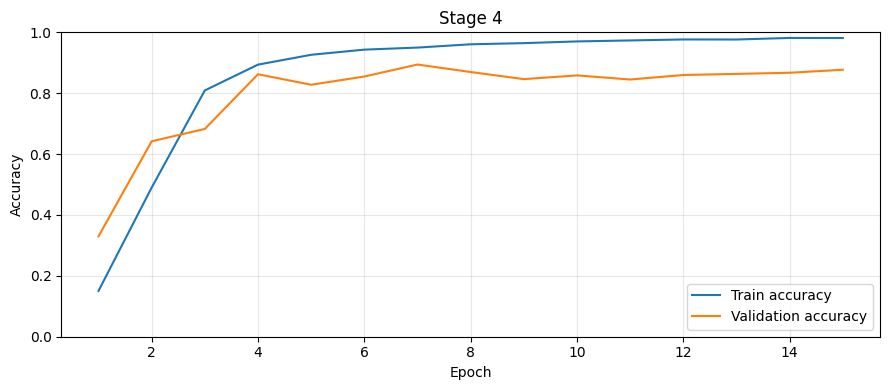

In [14]:
model_s4, history_s4 = run_stage(4, AUGMENTED_DIR)

<a id="stage5_superior"></a>
# STAGE 5: ADVANCED — 10.000 ẢNH TRAIN
Kế thừa cấu trúc bảo toàn `raw + center` của Stage 4 và mở rộng lên 1.000 ảnh/lớp (10.000 ảnh train) với `augment_native_train(..., advanced=True)`: tăng tỷ lệ căn giữa + biến thiên tương phản (55%), kết hợp co giãn bất đẳng hướng (`sx != sy`) và biến dạng nghiêng (`shear`) phân tầng theo độ phức tạp nét chữ (nhóm nhiều nét dọc `ii, iii, iv, vi, vii, viii, ix` dùng biên độ nhỏ hơn nhóm `i, v, x`), downsample bằng `LANCZOS`.

**Kết quả hiện tại:** checkpoint epoch 12 đạt validation **713/813 = 87,70%**, Label Book **41/52 = 78,85%**. Thực nghiệm đối chứng này chỉ ra rằng phép co giãn bất đẳng hướng và `shear` ở Stage 5 làm biến dạng nhẹ tỷ lệ hình học giữa các nét sổ dọc, khiến độ chính xác thấp hơn phép biến đổi đẳng hướng bảo toàn hình học của Stage 4 (`89,42%` validation, `82,69%` Label Book).

In [15]:
# Stage 5 tái sử dụng augment_native_train(..., advanced=True) đã tối ưu của Stage 4.
# Không tạo pipeline chuẩn hóa riêng cho validation hay Label Book.
assert_eval_unchanged()

In [16]:
SUPERIOR_DIR = build_native_mixed_train("stage5_native_mixed_train", 1000, advanced=True)

Train hỗn hợp: 10000 ảnh; giữ đủ raw + centered chuẩn hóa và augment ở độ phân giải gốc.


In [17]:
# Mọi stage dùng chung val_ds_raw và lb_ds_raw; không tạo tập đánh giá Superior riêng.
assert_eval_unchanged()

Found 10000 files belonging to 10 classes.
Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.1007 - loss: 2.3271
Epoch 1: val_accuracy improved from None to 0.19803, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5

Epoch 1: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5
313/313 ━━━━━━━━━━━━━━━━━━━━ 38s 96ms/step - accuracy: 0.1284 - loss: 2.2609 - val_accuracy: 0.1980 - val_loss: 2.0738
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3721 - loss: 1.6151
Epoch 2: val_accuracy improved from 0.19803 to 0.62362, saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5

Epoch 2: finished saving model to /content/deeplearningai-data-centric-competition/accuracy_results_v1/stage5_best_val_accuracy.weights.h5
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 

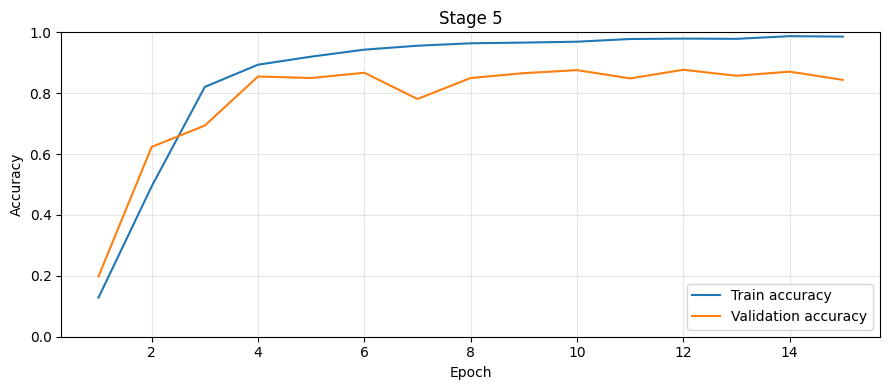

In [18]:
superior_model, history_s5 = run_stage(5, SUPERIOR_DIR)

<a id="stage6_eval"></a>
# PHẦN 6: TỔNG HỢP ACCURACY
Cả sáu stage đã chạy và đánh giá checkpoint có validation accuracy cao nhất, tách biệt với kết quả epoch cuối in trong log. Bảng so sánh dùng checkpoint được chọn, không trộn với epoch cuối. Label Book chỉ dùng báo cáo, không dùng chọn epoch hoặc stage.

## 1. CHỌN STAGE THEO VALIDATION ACCURACY
Chọn stage có accuracy validation cao nhất; không đọc Label Book khi lựa chọn.

In [19]:
assert_eval_unchanged()
missing=set(range(6))-BEST_CHECKPOINT_DETAILS.keys()
if missing:raise RuntimeError(f"Chưa có kết quả accuracy cho stage: {sorted(missing)}")
SELECTED_STAGE=max(sorted(BEST_CHECKPOINT_DETAILS),key=lambda i:BEST_CHECKPOINT_DETAILS[i]["validation"]["metrics"]["accuracy"])
SELECTED_DETAILS=BEST_CHECKPOINT_DETAILS[SELECTED_STAGE]
SELECTED_EPOCH=BEST_CHECKPOINT_EPOCHS[SELECTED_STAGE]
SELECTED_CHECKPOINT=FAIR_ROOT/f"stage{SELECTED_STAGE}_best_val_accuracy.weights.h5"
print(f"Chọn theo validation accuracy: Stage {SELECTED_STAGE}, epoch {SELECTED_EPOCH}")
display(pd.DataFrame({s:d["metrics"] for s,d in SELECTED_DETAILS.items()}).T)
def load_selected_model():
    if not SELECTED_CHECKPOINT.is_file():raise FileNotFoundError("Cần file weights từ runtime đã chạy; notebook không chứa weights.")
    model=build_fixed_vgg16_model();model.load_weights(str(SELECTED_CHECKPOINT));return model

Chọn theo validation accuracy: Stage 4, epoch 7


,accuracy,n_correct,n_samples
validation,0.894219,727.0,813.0
label_book,0.826923,43.0,52.0


## 2. ACCURACY CỦA MÔ HÌNH ĐƯỢC CHỌN
Stage 4, epoch 7: **validation 727/813 = 89,42%**, **Label Book 43/52 = 82,69%**. Số đúng/tổng kiểm tra trực tiếp công thức accuracy. Đây là checkpoint tốt nhất theo validation trong lần chạy hiện tại.

In [20]:
for split,title in [("validation","Validation gốc"),("label_book","Label Book gốc")]:
    m=SELECTED_DETAILS[split]["metrics"]
    print(f"{title}: {m['n_correct']}/{m['n_samples']} = {m['accuracy']:.2%}")

Validation gốc: 727/813 = 89.42%
Label Book gốc: 43/52 = 82.69%


## 3. SO SÁNH ACCURACY CÁC STAGE
Bảng và biểu đồ dưới dùng checkpoint đạt `val_accuracy` cao nhất của mỗi stage; nếu hòa giữ epoch đầu tiên. Cả sáu checkpoint đều đã có điểm Validation và Label Book đầy đủ.

Từ Stage 0 đến Stage 4, **Validation accuracy tăng đơn điệu qua từng bước**: `69,62%` (Stage 0) → `78,72%` (Stage 1) → `84,38%` (Stage 2) → `85,85%` (Stage 3) → `89,42%` (Stage 4), trước khi giảm nhẹ ở Stage 5 (`87,70%`) khi thêm biến dạng bất đẳng hướng/shear. Trên **Label Book**, độ chính xác cũng tăng liên tục từ `63,46%` (33/52 ở Stage 0) → `71,15%` (37/52 ở Stage 1) → `78,85%` (41/52 ở Stage 2) → đạt đỉnh `84,62%` (44/52 ở Stage 3) và đạt `82,69%` (43/52) tại mô hình được chọn Stage 4.

Accuracy-only — cùng tiêu chí val_accuracy cho mọi stage


,checkpoint_epoch,validation_accuracy,validation_correct,validation_total,label_book_accuracy,label_book_correct,label_book_total
stage,,,,,,,
0,15,0.6962,566,813,0.6346,33,52
1,14,0.7872,640,813,0.7115,37,52
2,11,0.8438,686,813,0.7885,41,52
3,15,0.8585,698,813,0.8462,44,52
4,7,0.8942,727,813,0.8269,43,52
5,12,0.8770,713,813,0.7885,41,52


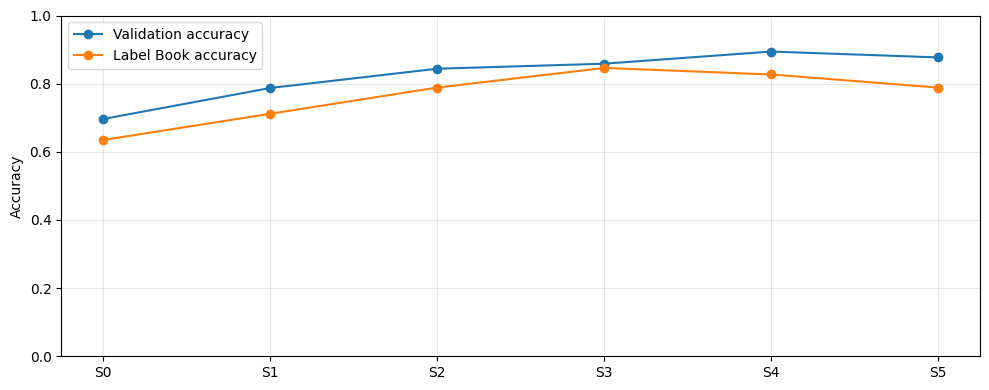

In [21]:
assert_eval_unchanged()
rows=[]
for i in range(6):
    v=BEST_CHECKPOINT_DETAILS[i]["validation"]["metrics"]
    b=BEST_CHECKPOINT_DETAILS[i]["label_book"]["metrics"]
    rows.append(dict(stage=i,checkpoint_epoch=BEST_CHECKPOINT_EPOCHS[i],
                     validation_accuracy=v["accuracy"],validation_correct=v["n_correct"],validation_total=v["n_samples"],
                     label_book_accuracy=b["accuracy"],label_book_correct=b["n_correct"],label_book_total=b["n_samples"]))
table=pd.DataFrame(rows).set_index("stage")
print("Accuracy-only — cùng tiêu chí val_accuracy cho mọi stage")
display(table.round(4));table.to_csv(FAIR_ROOT/"accuracy_comparison.csv")
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(table.index,table["validation_accuracy"],marker="o",label="Validation accuracy")
ax.plot(table.index,table["label_book_accuracy"],marker="o",label="Label Book accuracy")
ax.set_xticks(range(6),[f"S{i}" for i in range(6)]);ax.set_ylim(0,1);ax.set_ylabel("Accuracy")
ax.legend();ax.grid(alpha=0.3);fig.tight_layout();plt.show()

## 4. PHÂN TÍCH LỖI (CONFUSION MATRIX & ACCURACY TỪNG LỚP)
Đánh giá chi tiết mô hình được chọn (`SELECTED_STAGE`) trên `Validation` và `Label Book` theo từng chữ số La Mã để xác định các cặp lớp dễ nhầm lẫn.

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 66 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


=== Validation gốc (Stage 4, epoch 7) ===


,correct,total,accuracy
class_name,,,
i,78,82,0.9512
ii,69,81,0.8519
iii,75,79,0.9494
iv,65,84,0.7738
v,82,83,0.9880
vi,75,82,0.9146
vii,72,77,0.9351
viii,67,83,0.8072
ix,67,81,0.8272


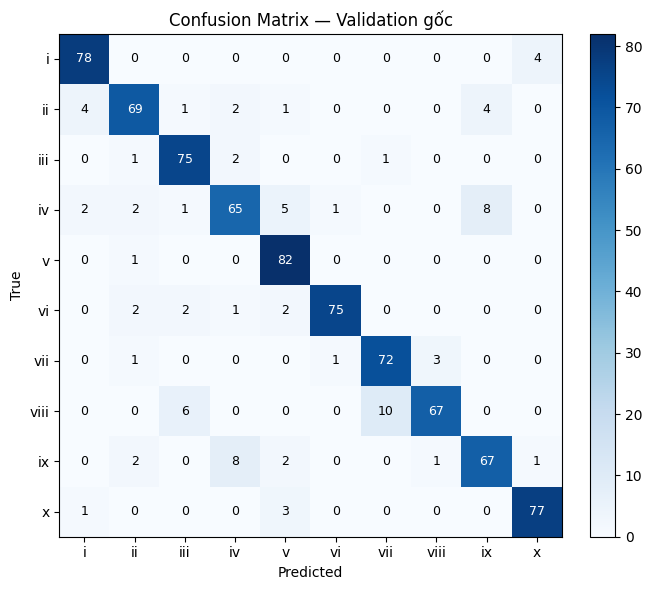

=== Label Book gốc (Stage 4, epoch 7) ===


,correct,total,accuracy
class_name,,,
i,5,5,1.0000
ii,4,5,0.8000
iii,5,6,0.8333
iv,4,5,0.8000
v,5,6,0.8333
vi,4,5,0.8000
vii,4,5,0.8000
viii,5,5,1.0000
ix,4,5,0.8000


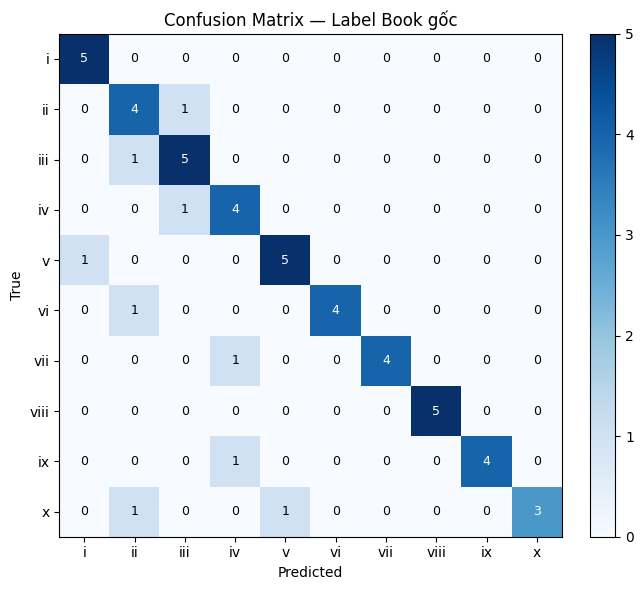

In [22]:
assert_eval_unchanged()
selected_model = load_selected_model()

def analyze_errors(model, dataset, title, prefix):
    y_true, y_pred = [], []
    for images, labels in dataset:
        y_true.append(np.asarray(labels).argmax(axis=1))
        y_pred.append(np.asarray(model(images, training=False)).argmax(axis=1))
    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)

    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)

    rows = []
    for idx, cls in enumerate(CLASS_NAMES):
        total = int(cm[idx].sum())
        correct = int(cm[idx, idx])
        rows.append(dict(
            class_name=cls,
            correct=correct,
            total=total,
            accuracy=correct / total if total else 0.0,
        ))
    df_cls = pd.DataFrame(rows).set_index("class_name")
    df_cls.to_csv(FAIR_ROOT / f"{prefix}_per_class_accuracy.csv")
    print(f"=== {title} (Stage {SELECTED_STAGE}, epoch {SELECTED_EPOCH}) ===")
    display(df_cls.round(4))

    fig, ax = plt.subplots(figsize=(7.5, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"Confusion Matrix — {title}")
    thresh = cm.max() / 2.0 if cm.max() > 0 else 0.0
    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center",
                    color="white" if cm[r, c] > thresh else "black", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(FAIR_ROOT / f"{prefix}_confusion_matrix.png", dpi=130)
    plt.show()
    return cm, df_cls

val_cm, val_cls_df = analyze_errors(selected_model, val_ds_raw, "Validation gốc", "selected_val")
lb_cm, lb_cls_df = analyze_errors(selected_model, lb_ds_raw, "Label Book gốc", "selected_lb")

## 5. KẾT LUẬN

- **Chọn Stage 4, epoch 7 theo validation accuracy:** đạt **727/813 = 89,42%** trên Validation và **43/52 = 82,69%** trên Label Book. So với Baseline (Stage 0), mô hình được chọn tăng **+19,80 điểm phần trăm** (+161 ảnh đúng) trên Validation và tăng **+19,23 điểm phần trăm** (+10 ảnh đúng) trên Label Book.
- **Stage 3, epoch 15 đạt Label Book cao nhất trong sáu stage:** **44/52 = 84,62%** (Validation đạt **698/813 = 85,85%**). Đây là quan sát thực nghiệm củng cố hiệu quả của bước cân bằng lớp và biến đổi affine bảo toàn biên, không dùng để thay đổi quy tắc chọn mô hình theo Validation.
- **Đóng góp rõ rệt của từng giai đoạn Data-Centric AI:**
  1. **Stage 1 (Tinh lọc & sửa nhãn thủ công 1.871 ảnh):** Loại bỏ nhiễu nhãn và các cặp trùng lặp chéo lớp giúp tăng vọt cả Validation (+9,10%) lẫn Label Book (+7,69%) dù số ảnh ít hơn Baseline.
  2. **Stage 2 (Khử nhiễu hạt/lưới/đốm biên & căn giữa 3.742 ảnh):** Giải quyết triệt để hiện tượng lệch bounding box do nhiễu viền và lưới tọa độ, nâng tiếp Validation thêm +5,66% và Label Book thêm +7,69%.
  3. **Stage 3 & Stage 4 (Cân bằng phân phối lớp & Augmentation đẳng hướng ở độ phân giải gốc):** Bảo toàn đồng thời bản `raw` + `center` chuẩn hóa và xoay/co giãn đẳng hướng ở độ phân giải cao trước khi thu nhỏ bằng `LANCZOS` giúp mô hình đạt đỉnh Validation **89,42%** và Label Book **82,69%–84,62%**.
  4. **Stage 5 (10.000 ảnh với co giãn bất đẳng hướng & shear):** Đạt 87,70% Validation và 78,85% Label Book, chứng minh rằng với chữ số La Mã nhiều nét song song (`ii, iii, iv, vi, vii, viii, ix`), phép biến đổi đẳng hướng ở Stage 4 bảo toàn đặc trưng hình học tốt hơn biến dạng shear.
- Giữ nguyên tuyệt đối Validation (813 ảnh) và Label Book (52 ảnh). Audit ghi nhận 49 ảnh train trùng validation (0 ảnh trùng Label Book); chỉ báo cáo minh bạch, không tự lọc.